# HPC compression study — local analysis

Copy the bundle from Dante, then set `BUNDLE` below. This notebook reads JSON and histories only: no training, dataset access, checkpoint loading, or test evaluation. HPC absolute paths in the saved state are treated as provenance.

Only completed runs enter comparisons. Error bars show sample standard deviation across seeds, **not confidence intervals**. Missing or capped runs are displayed separately. The 0.05 decision comes from the saved validation selection. With a fixed eight-qubit circuit, the curves measure representation size and circuit application count, not scaling in qubit count.

In [1]:
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = Path.cwd().parent
BUNDLE = PROJECT / "results" / "compression_sweep"
ROOT = BUNDLE / "study" if (BUNDLE / "study" / "study.json").exists() else BUNDLE
assert (ROOT / "study.json").exists(), f"Set BUNDLE to the copied results directory: {ROOT}"


In [2]:
state = json.loads((ROOT / "study.json").read_text(encoding="utf-8"))
seeds = state["configuration"]["experiment"]["training"]["seeds"]
levels = state["configuration"]["levels"]
selection = state.get("selection")
rows = []
for job in state["jobs"].values():
    row = {k: v for k, v in job.items() if k != "attempts"}
    attempts = job.get("attempts", [])
    for field in ("peak_process_rss_bytes", "peak_gpu_allocated_bytes", "peak_gpu_reserved_bytes"):
        row[field] = max((a.get(field, 0) for a in attempts), default=0)
    rows.append(row)
columns = ["key", "level", "variant", "seed", "status", "stopping_reason", "feature_values",
           "compression_axis", "macro_f1", "elapsed_seconds", "time_to_best_seconds",
           "peak_process_rss_bytes", "peak_gpu_allocated_bytes", "peak_gpu_reserved_bytes"]
runs = pd.DataFrame(rows).reindex(columns=columns)
complete = runs.loc[runs.status.eq("completed")].copy()
print(f"Study: {state['id']} | expected seeds: {seeds}")
print(f"Study runtime: {state['elapsed_seconds']/3600:.2f} h | preparation: {state['preparation_seconds']/60:.1f} min")
print("Last stop:", state.get("last_stop"), "| expansion stop:", state.get("expansion_stopped"))
display(runs.groupby(["variant", "status"]).size().rename("runs").to_frame())
display(runs.loc[~runs.status.eq("completed"), ["key", "status", "stopping_reason", "elapsed_seconds"]])

Study: compression_a273a0297ce0 | expected seeds: [42, 1324, 987654]
Study runtime: 130.57 h | preparation: 0.1 min
Last stop: scheduler_interruption: SIGUSR1 | expansion stop: None


runs
variant               status           
compression_cnn       completed      18
compression_patch_cnn completed      10
compression_qufex     completed      10
                      interrupted     1
direct_cnn            completed       3

,key,status,stopping_reason,elapsed_seconds
41,M2_compression_qufex_seed1324,interrupted,SIGUSR1,15242.042178


In [3]:
runs.columns

Index(['key', 'level', 'variant', 'seed', 'status', 'stopping_reason',
       'feature_values', 'compression_axis', 'macro_f1', 'elapsed_seconds',
       'time_to_best_seconds', 'peak_process_rss_bytes',
       'peak_gpu_allocated_bytes', 'peak_gpu_reserved_bytes'],
      dtype='str')

## Validation selection and compression curve

M0–M3 vary spatial resolution; M4–M5 also reduce channels. The direct CNN is an additional reference. A mean degradation of exactly 0.05 is acceptable. The notebook does not make a new selection or replace incomplete seeds.

In [4]:
if selection:
    print("Saved selected level:", selection["selected_level"])
    display(pd.DataFrame(selection["decisions"]))
else:
    print("No selection yet: all configured classical level/seed runs must complete.")

summary = complete.groupby(["level", "variant", "feature_values", "compression_axis"], dropna=False).agg(
    macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
    seeds_completed=("seed", "nunique"), runtime_seconds=("elapsed_seconds", "mean"),
    gpu_gib=("peak_gpu_allocated_bytes", lambda s: s.mean() / 2**30),
    rss_gib=("peak_process_rss_bytes", lambda s: s.mean() / 2**30),
).reset_index()
display(summary)
full = summary.loc[summary.seeds_completed.eq(len(seeds))]


Saved selected level: M5


,level,scores,mean_macro_f1,mean_drop,drop_std,acceptable
0,M0,"[0.7977301139767858, 0.7996850862439007, 0.810...",0.802524,0.000000,0.000000,True
1,M1,"[0.7927994551266889, 0.7975462219227417, 0.790...",0.793729,0.008796,0.009218,True
2,M2,"[0.804747095335823, 0.8035403468999905, 0.8011...",0.803138,-0.000614,0.008501,True
3,M3,"[0.8050009639845624, 0.8056893728054725, 0.806...",0.805812,-0.003288,0.005837,True
4,M4,"[0.7962696537283342, 0.8114122580674947, 0.789...",0.798909,0.003615,0.016525,True
5,M5,"[0.7977193870430016, 0.8010152002580563, 0.796...",0.798362,0.004162,0.008379,True


,level,variant,feature_values,compression_axis,macro_f1_mean,macro_f1_std,seeds_completed,runtime_seconds,gpu_gib,rss_gib
0,M0,compression_cnn,4096,spatial,0.802524,0.006683,3,3810.184639,0.030438,2.447622
1,M1,compression_cnn,2304,spatial,0.793729,0.003448,3,3513.101170,0.030128,2.442445
2,M2,compression_cnn,1024,spatial,0.803138,0.001844,3,4629.742325,0.030102,2.444534
3,M2,compression_patch_cnn,1024,spatial,0.808213,NaN,1,12121.041963,0.063908,2.887672
4,M2,compression_qufex,1024,spatial,0.790619,NaN,1,49945.539206,0.122323,2.610600
5,M3,compression_cnn,256,spatial,0.805812,0.000879,3,6488.069218,0.030087,2.450488
6,M3,compression_patch_cnn,256,spatial,0.796467,0.005530,3,8721.233741,0.025936,2.687904
7,M3,compression_qufex,256,spatial,0.796697,0.007635,3,27143.406864,0.049541,2.638341
8,M4,compression_cnn,128,channel,0.798909,0.011414,3,4584.497674,0.024678,2.620235
9,M4,compression_patch_cnn,128,channel,0.801036,0.003310,3,6408.915692,0.024235,2.629114


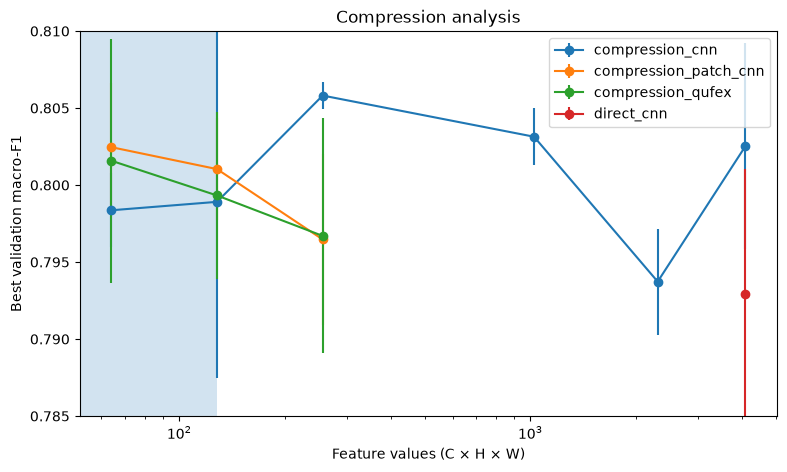

In [5]:

fig, ax = plt.subplots(figsize=(9, 5))

channels_compression = full[full.level.eq("M4")].iloc[0].feature_values
ax.fill_betweenx([0, 1], 0, channels_compression, alpha=0.2)

for variant, group in full.groupby("variant"):
    group = group.sort_values("feature_values")
    ax.errorbar(group.feature_values, group.macro_f1_mean,
                yerr=group.macro_f1_std.fillna(0), marker="o", label=variant)
    # for row in group.itertuples():
    #     if row.compression_axis == "channel":
    #         ax.annotate(row.level + " (channels)", (row.feature_values, row.macro_f1_mean),
    #                     xytext=(4, 6), textcoords="offset points", fontsize=8)
# if selection:
#     floor = np.mean(selection["reference_scores"]) - selection["threshold"]
#     ax.axhline(floor, color="gray", linestyle="--", label="M0 − 0.05 acceptance floor")
ax.set(xlabel="Feature values (C × H × W)", ylabel="Best validation macro-F1",
       title="Compression analysis")
ax.annotate("Channel compression", (channels_compression - 100, 0.789), fontsize=8)
ax.set_ylim(0.785, 0.810)
ax.set_xscale("log")

if ax.get_legend_handles_labels()[0]:
    ax.legend()
plt.show()

## Paired quantum–classical differences

Pair by level and seed; positive values favor QuFeX. Full CNN and patch CNN answer different control questions. Partial pairs remain visible in the table, but the plot requires all configured seeds.

,level,seed,control,feature_values,delta
0,M5,42,compression_cnn,64,-0.005277
1,M5,1324,compression_cnn,64,0.005694
2,M5,987654,compression_cnn,64,0.009235
3,M4,42,compression_cnn,128,0.003476
4,M4,1324,compression_cnn,128,-0.006900
5,M4,987654,compression_cnn,128,0.004667
6,M5,42,compression_patch_cnn,64,-0.013238
7,M5,1324,compression_patch_cnn,64,0.002723
8,M5,987654,compression_patch_cnn,64,0.007875
9,M4,42,compression_patch_cnn,128,-0.004934


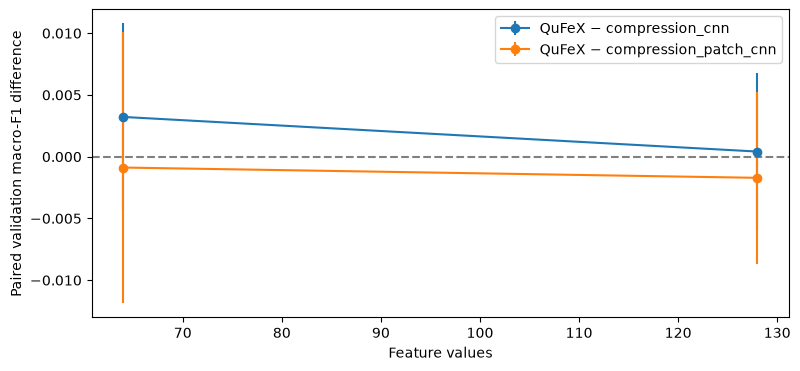

In [4]:
pair_rows = []
quantum = complete.loc[complete.variant.eq("compression_qufex")]
for control in ("compression_cnn", "compression_patch_cnn"):
    classical = complete.loc[complete.variant.eq(control)]
    pairs = quantum.merge(classical, on=["level", "seed"], suffixes=("_q", "_c"),
                          validate="one_to_one")
    for row in pairs.itertuples():
        pair_rows.append(dict(level=row.level, seed=row.seed, control=control,
                              feature_values=row.feature_values_q,
                              delta=row.macro_f1_q - row.macro_f1_c))
pairs = pd.DataFrame(pair_rows, columns=["level", "seed", "control", "feature_values", "delta"])
display(pairs)
paired_summary = pairs.groupby(["level", "control", "feature_values"]).agg(
    mean=("delta", "mean"), std=("delta", "std"), count=("seed", "nunique")).reset_index()
fig, ax = plt.subplots(figsize=(9, 4))
for control, group in paired_summary.loc[paired_summary["count"].eq(len(seeds))].groupby("control"):
    group = group.sort_values("feature_values")
    ax.errorbar(group.feature_values, group["mean"], yerr=group["std"].fillna(0),
                marker="o", label=f"QuFeX − {control}")
ax.axhline(0, color="gray", linestyle="--")
ax.set(xlabel="Feature values", ylabel="Paired validation macro-F1 difference")
if ax.get_legend_handles_labels()[0]:
    ax.legend()
plt.show()

## Cost and learning histories

Runtime includes attempted work on interrupted epochs. GPU allocation and process RSS are measured separately; a circuit chunk size does not bound the complete autograd graph. Profiling estimates are estimates of training steps, not evidence of convergence.

,level,status,elapsed_seconds,stopping_reason,step_seconds_mean,step_seconds_std,warmup_steps,measured_steps,estimated_training_epoch_seconds,estimated_max_training_seconds,estimate_scope,runtime
0,M5,completed,6.436449,None,0.051977,0.007876,5,20,398.145803,19907.290131,training steps only; excludes validation/check...,{'process_started_at_utc': '2026-09-26T08:20:1...
1,M4,completed,6.164882,None,0.055874,0.010809,5,20,427.996467,21399.823372,training steps only; excludes validation/check...,{'process_started_at_utc': '2026-09-28T10:22:1...
2,M3,completed,5.035786,None,0.067319,0.001998,5,20,515.665983,25783.299169,training steps only; excludes validation/check...,{'process_started_at_utc': '2026-09-28T10:22:1...


,key,status,elapsed_seconds,time_to_best_seconds,peak_process_rss_bytes,peak_gpu_allocated_bytes
0,M0_compression_cnn_seed42,completed,2571.325083,1724.741553,2627284992,47354880
1,M0_compression_cnn_seed1324,completed,3370.816296,2508.312338,2626166784,25347072
2,M0_compression_cnn_seed987654,completed,5488.412537,5266.223224,2630889472,25347072
3,M1_compression_cnn_seed42,completed,3664.854695,2755.774671,2622205952,47240192
4,M1_compression_cnn_seed1324,completed,4095.700944,3163.438426,2622205952,24904192
5,M1_compression_cnn_seed987654,completed,2778.747871,1813.424030,2623254528,24904192
6,M2_compression_cnn_seed42,completed,5321.321931,4337.634436,2624544768,47158272
7,M2_compression_cnn_seed1324,completed,4319.844018,3288.400568,2624921600,24904192
8,M2_compression_cnn_seed987654,completed,4248.061026,3222.550868,2624929792,24904192
9,M3_compression_cnn_seed42,completed,6514.036884,6250.829291,2630909952,47109120


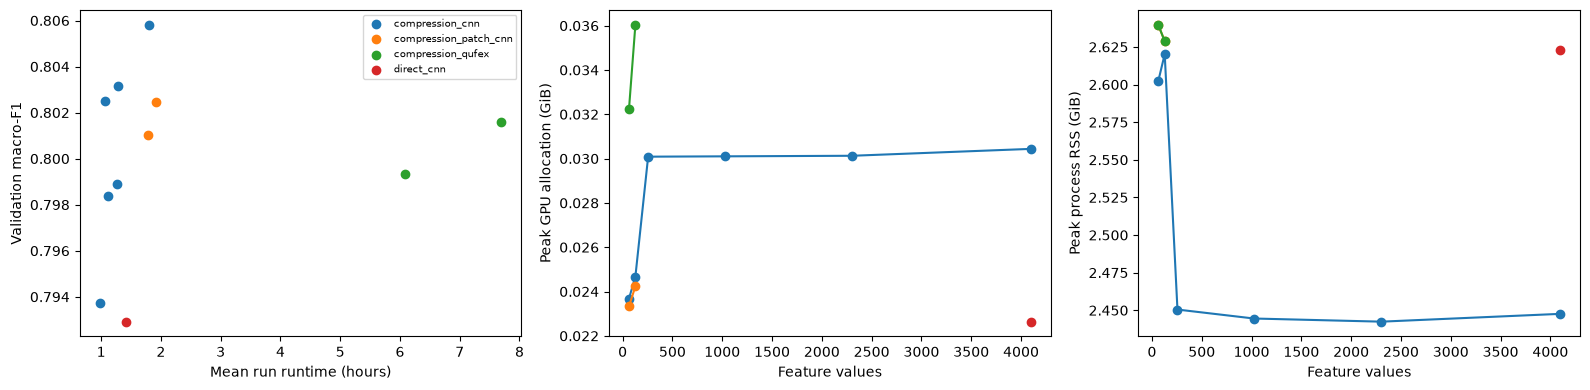

M0_compression_cnn_seed42


,epoch,train_loss,validation_loss,learning_rate,next_learning_rate,epoch_seconds,accuracy,macro_precision,macro_recall,balanced_accuracy,macro_f1,weighted_f1,cumulative_elapsed_seconds
0,0,0.867173,0.790647,0.001,0.001,121.151027,0.625695,0.589973,0.632143,0.632143,0.565061,0.609627,126.043393
1,1,0.719224,0.688769,0.001,0.001,106.573153,0.703221,0.670798,0.699266,0.699266,0.665587,0.701155,232.670100
2,2,0.668259,0.712779,0.001,0.001,106.392077,0.691646,0.660050,0.697532,0.697532,0.667300,0.694924,339.113377
3,3,0.637134,0.609478,0.001,0.001,106.901087,0.769096,0.753208,0.740604,0.740604,0.746265,0.768855,446.067542
4,4,0.610698,0.611929,0.001,0.001,106.802032,0.751580,0.719755,0.746216,0.746216,0.726860,0.750410,552.918162
5,5,0.592953,0.562536,0.001,0.001,107.405336,0.785317,0.765690,0.763954,0.763954,0.761572,0.780589,660.358343
6,6,0.578817,0.584742,0.001,0.001,106.651662,0.790724,0.793427,0.750808,0.750808,0.765499,0.783434,767.067504
7,7,0.570758,0.541437,0.001,0.001,106.675313,0.801767,0.796394,0.772208,0.772208,0.780566,0.796387,873.801508
8,8,0.564526,0.560342,0.001,0.001,105.598902,0.795522,0.797677,0.760069,0.760069,0.770878,0.786958,979.456479
9,9,0.555183,0.543640,0.001,0.001,106.741899,0.800853,0.811303,0.763378,0.763378,0.781837,0.798522,1086.232946


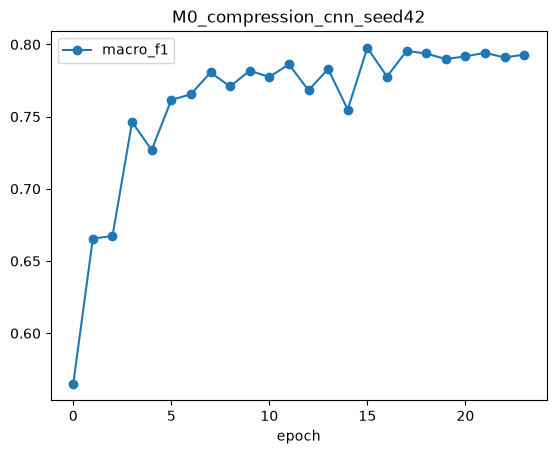

In [5]:
display(pd.DataFrame(state.get("profiles", {}).values()))
display(runs[["key", "status", "elapsed_seconds", "time_to_best_seconds",
              "peak_process_rss_bytes", "peak_gpu_allocated_bytes"]])
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for variant, group in full.groupby("variant"):
    axes[0].scatter(group.runtime_seconds / 3600, group.macro_f1_mean, label=variant)
    group = group.sort_values("feature_values")
    axes[1].plot(group.feature_values, group.gpu_gib, marker="o", label=variant)
    axes[2].plot(group.feature_values, group.rss_gib, marker="o", label=variant)
axes[0].set(xlabel="Mean run runtime (hours)", ylabel="Validation macro-F1")
axes[1].set(xlabel="Feature values", ylabel="Peak GPU allocation (GiB)")
axes[2].set(xlabel="Feature values", ylabel="Peak process RSS (GiB)")
if axes[0].get_legend_handles_labels()[0]:
    axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

# Select any run key from the table; paths are rebuilt relative to the copied bundle.
RUN_KEY = next(iter(state["jobs"]), None)
if RUN_KEY:
    history_path = ROOT / "jobs" / f"{state['id']}_{RUN_KEY}" / "history.json"
    if history_path.exists():
        history = pd.read_json(history_path)
        print(RUN_KEY)
        display(history)
        if "macro_f1" in history:
            history.plot(x="epoch", y="macro_f1", marker="o", title=RUN_KEY)
            plt.show()

## Frozen test results (if explicitly evaluated on the HPC)

This cell only reads results already saved by the explicit `evaluate` stage. It never evaluates or selects checkpoints. Test scores must not be used to revise the compression threshold or expansion order.

In [6]:
manifest = state.get("evaluation_manifest") or []
allowed = {item["key"] for item in manifest}
test_rows = []
for key, result in state.get("evaluations", {}).items():
    if key in allowed and result["status"] == "completed":
        test_rows.append({"key": key, **result["metrics"]})
if test_rows:
    display(pd.json_normalize(test_rows))
else:
    print("No completed frozen test evaluations in this bundle.")
print("Frozen checkpoints:", len(manifest), "| completed test evaluations:", len(test_rows))

No completed frozen test evaluations in this bundle.
Frozen checkpoints: 0 | completed test evaluations: 0
